In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

## Bài toán 1 – Nhiệm vụ 1: Khám phá dữ liệu COVID (Our World in Data)

In [35]:
covid_data = pd.read_csv("data/covid-data.csv",
                         usecols=['code','continent','country','date','total_cases','new_cases'])
covid_data = covid_data.rename(columns={'country':'location', 'code':'iso_code'})
covid_data = covid_data[['iso_code','continent','location','date','total_cases','new_cases']]
covid_data.head(5)

,iso_code,continent,location,date,total_cases,new_cases
0,AFG,Asia,Afghanistan,2020-01-01,NaN,NaN
1,AFG,Asia,Afghanistan,2020-01-02,NaN,NaN
2,AFG,Asia,Afghanistan,2020-01-03,NaN,NaN
3,AFG,Asia,Afghanistan,2020-01-04,0.0,0.0
4,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0


In [36]:
covid_data.dtypes

iso_code           str
continent          str
location           str
date               str
total_cases    float64
new_cases      float64
dtype: object

In [37]:
covid_data.shape

(617667, 6)

In [38]:
print("Số giá trị thiếu của new_cases:", covid_data["new_cases"].isna().sum())
print("np.mean       :", np.mean(covid_data["new_cases"]))
print("np.std        :", np.std(covid_data["new_cases"]))
print("np.median     :", np.median(covid_data["new_cases"]))
print("np.percentile :", np.percentile(covid_data["new_cases"], 60))
print("np.quantile   :", np.quantile(covid_data["new_cases"], 0.75))
print("stats.iqr     :", stats.iqr(covid_data["new_cases"]))

Số giá trị thiếu của new_cases: 17044
np.mean       : 9056.902492911528
np.std        : 108826.76225180391
np.median     : nan
np.percentile : nan
np.quantile   : nan
stats.iqr     : nan


In [39]:
new_cases = covid_data["new_cases"].dropna()

data_mean     = np.mean(new_cases)                 # trung bình
data_median   = np.median(new_cases)               # trung vị
data_mode     = stats.mode(new_cases, keepdims=False)   # mode
data_variance = np.var(new_cases)                  # phương sai (tổng thể, ddof=0)
data_sd       = np.std(new_cases)                  # độ lệch chuẩn
data_max      = np.max(new_cases)
data_min      = np.min(new_cases)
data_range    = data_max - data_min                # range
data_percentile = np.percentile(new_cases, 60)     # phân vị 60
data_quartile = np.quantile(new_cases, 0.75)       # Q3
q1, q2, q3    = np.quantile(new_cases, [0.25, 0.5, 0.75])
data_IQR      = stats.iqr(new_cases)               # IQR = Q3 - Q1

result = pd.Series({
    'count': len(new_cases), 'mean': data_mean, 'median': data_median,
    'mode': data_mode.mode, 'mode_count': data_mode.count,
    'variance': data_variance, 'std': data_sd,
    'min': data_min, 'max': data_max, 'range': data_range,
    'P60': data_percentile, 'Q1': q1, 'Q2': q2, 'Q3': data_quartile, 'IQR': data_IQR})
result.apply(lambda v: f"{v:,.2f}")

count                600,623.00
mean                   9,056.90
median                     0.00
mode                       0.00
mode_count           401,015.00
variance      11,843,264,182.21
std                  108,826.76
min                        0.00
max                8,401,906.00
range              8,401,906.00
P60                        0.00
Q1                         0.00
Q2                         0.00
Q3                        25.00
IQR                       25.00
dtype: str

Skewness của new_cases: 35.7


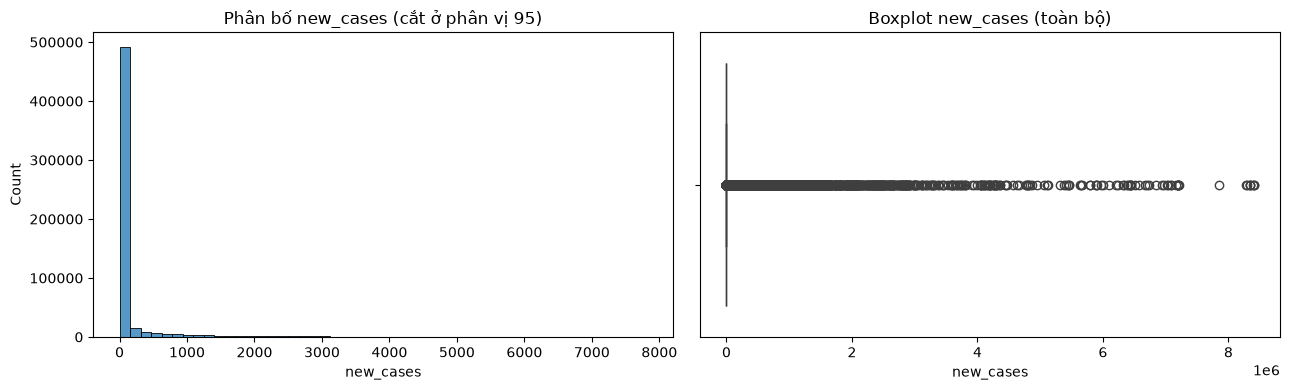

In [40]:
print("Skewness của new_cases:", round(stats.skew(new_cases), 2))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(new_cases[new_cases < new_cases.quantile(0.95)], bins=50, ax=ax[0])
ax[0].set_title('Phân bố new_cases (cắt ở phân vị 95)'); ax[0].set_xlabel('new_cases')
sns.boxplot(x=new_cases, ax=ax[1]); ax[1].set_title('Boxplot new_cases (toàn bộ)')
plt.tight_layout()

In [41]:
print("Các dòng tổng hợp (continent = NaN):", covid_data['continent'].isna().sum(),
      "dòng,", covid_data[covid_data['continent'].isna()]['location'].nunique(), "'địa điểm'")
only_countries = covid_data.dropna(subset=['continent'])['new_cases'].dropna()
compare = pd.DataFrame({
    'Toàn bộ dữ liệu': [new_cases.mean(), new_cases.median(), new_cases.std(), new_cases.max(), len(new_cases)],
    'Chỉ quốc gia (có continent)': [only_countries.mean(), only_countries.median(), only_countries.std(), only_countries.max(), len(only_countries)]},
    index=['mean','median','std','max','count'])
compare.round(2)

Các dòng tổng hợp (continent = NaN): 45240 dòng, 23 'địa điểm'


,Toàn bộ dữ liệu,Chỉ quốc gia (có continent)
mean,9056.90,1387.32
median,0.00,0.00
std,108826.85,29771.93
max,8401906.00,6966046.00
count,600623.00,561727.00


## Bài toán 1 – Nhiệm vụ 2: Khám phá và xử lý dữ liệu Marketing Campaign

In [42]:
marketing_data = pd.read_csv("data/marketing_campaign.csv", sep='\t')
print("Kích thước ban đầu:", marketing_data.shape)
marketing_data = marketing_data[['ID','Year_Birth','Education','Marital_Status','Income',
                                 'Kidhome','Teenhome','Dt_Customer','Recency',
                                 'NumStorePurchases','NumWebVisitsMonth']]
marketing_data.head()

Kích thước ban đầu: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,NumStorePurchases,NumWebVisitsMonth
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,4,7
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,2,5
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,10,4
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,4,6
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,6,5


In [43]:
print("Số dòng trùng lặp:", marketing_data.duplicated().sum())
marketing_data_duplicate = marketing_data.drop_duplicates()
print("Sau drop_duplicates:", marketing_data_duplicate.shape)
# xóa dòng ở vị trí index 1 và xóa cột Year_Birth (kết quả chỉ trả về bản mới, không sửa dữ liệu gốc)
print("Sau khi xóa dòng 1:", marketing_data.drop(labels=[1], axis=0).shape)
print("Sau khi xóa cột Year_Birth:", marketing_data.drop(labels=['Year_Birth'], axis=1).shape)

Số dòng trùng lặp: 0
Sau drop_duplicates: (2240, 11)
Sau khi xóa dòng 1: (2239, 11)
Sau khi xóa cột Year_Birth: (2240, 10)


In [44]:
marketing_data.isnull().sum()

ID                    0
Year_Birth            0
Education             0
Marital_Status        0
Income               24
Kidhome               0
Teenhome              0
Dt_Customer           0
Recency               0
NumStorePurchases     0
NumWebVisitsMonth     0
dtype: int64

In [45]:
marketing_data['Teenhome_replaced'] = marketing_data['Teenhome'].replace(
    [0, 1, 2], ['has no teen', 'has teen', 'has teen'])
marketing_data['Teenhome_replaced'].value_counts()

Teenhome_replaced
has no teen    1158
has teen       1082
Name: count, dtype: int64

In [46]:
income_raw = marketing_data['Income']
print("Mean khi bỏ NaN       :", round(income_raw.mean(), 2))
print("Mean khi fillna(0)    :", round(income_raw.fillna(0).mean(), 2))
print("Mean khi fillna(median):", round(income_raw.fillna(income_raw.median()).mean(), 2))

marketing_data['Income'] = marketing_data['Income'].fillna(0)                 # theo lab
marketing_data['Income_changed'] = marketing_data['Income'].astype(int)       # float -> int
marketing_data[['Income','Income_changed']].dtypes

Mean khi bỏ NaN       : 52247.25
Mean khi fillna(0)    : 51687.46
Mean khi fillna(median): 52237.98


Income            float64
Income_changed      int64
dtype: object

In [47]:
marketing_raw = pd.read_csv("data/marketing_campaign.csv", sep='\t')[marketing_data.columns[:11]]
marketing_data_withoutna = marketing_raw.dropna(how='any')
print("Trước:", marketing_raw.shape, "| Sau dropna:", marketing_data_withoutna.shape)

Trước: (2240, 11) | Sau dropna: (2216, 11)


## Bài tập thực hành 1 – Thống kê mô tả tập dữ liệu Red Wine Quality

In [48]:
wine = pd.read_csv("data/winequality-red.csv")
print("Kích thước:", wine.shape)
wine.head(10)

Kích thước: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5
6,7.9,0.60,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5
7,7.3,0.65,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7
8,7.8,0.58,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7
9,7.5,0.50,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5


In [49]:
wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [50]:
print("Giá trị thiếu:", wine.isnull().sum().sum())
print("Dòng trùng lặp:", wine.duplicated().sum())

Giá trị thiếu: 0
Dòng trùng lặp: 240


In [51]:
wine.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


In [52]:
def thong_ke(df):
    s = pd.DataFrame({
        'mean': df.mean(), 'median': df.median(), 'mode': df.mode().iloc[0],
        'variance': df.var(), 'std': df.std(),
        'min': df.min(), 'max': df.max(), 'range': df.max() - df.min(),
        'Q1': df.quantile(0.25), 'Q3': df.quantile(0.75)})
    s['IQR'] = s['Q3'] - s['Q1']
    s['skew'] = df.skew()
    return s
thong_ke(wine).round(3)

,mean,median,mode,variance,std,min,max,range,Q1,Q3,IQR,skew
fixed acidity,8.320,7.900,7.200,3.031,1.741,4.600,15.900,11.300,7.100,9.200,2.100,0.983
volatile acidity,0.528,0.520,0.600,0.032,0.179,0.120,1.580,1.460,0.390,0.640,0.250,0.672
citric acid,0.271,0.260,0.000,0.038,0.195,0.000,1.000,1.000,0.090,0.420,0.330,0.318
residual sugar,2.539,2.200,2.000,1.988,1.410,0.900,15.500,14.600,1.900,2.600,0.700,4.541
chlorides,0.087,0.079,0.080,0.002,0.047,0.012,0.611,0.599,0.070,0.090,0.020,5.680
free sulfur dioxide,15.875,14.000,6.000,109.415,10.460,1.000,72.000,71.000,7.000,21.000,14.000,1.251
total sulfur dioxide,46.468,38.000,28.000,1082.102,32.895,6.000,289.000,283.000,22.000,62.000,40.000,1.516
density,0.997,0.997,0.997,0.000,0.002,0.990,1.004,0.014,0.996,0.998,0.002,0.071
pH,3.311,3.310,3.300,0.024,0.154,2.740,4.010,1.270,3.210,3.400,0.190,0.194
sulphates,0.658,0.620,0.600,0.029,0.170,0.330,2.000,1.670,0.550,0.730,0.180,2.429


In [53]:
print(wine['quality'].value_counts().sort_index())
print()
print((wine['quality'].value_counts(normalize=True).sort_index()*100).round(1).astype(str) + ' %')

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

quality
3     0.6 %
4     3.3 %
5    42.6 %
6    39.9 %
7    12.4 %
8     1.1 %
Name: proportion, dtype: str


In [54]:
def dem_ngoai_lai(df):
    rs = {}
    for c in df.columns:
        q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
        rs[c] = int(((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum())
    return pd.Series(rs, name='số giá trị ngoại lai')
dem_ngoai_lai(wine.drop(columns='quality'))

fixed acidity            49
volatile acidity         19
citric acid               1
residual sugar          155
chlorides               112
free sulfur dioxide      30
total sulfur dioxide     55
density                  45
pH                       35
sulphates                59
alcohol                  13
Name: số giá trị ngoại lai, dtype: int64

In [55]:
wine.groupby('quality').mean().round(3)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,8.360,0.885,0.171,2.635,0.122,11.000,24.900,0.997,3.398,0.570,9.955
4,7.779,0.694,0.174,2.694,0.091,12.264,36.245,0.997,3.382,0.596,10.265
5,8.167,0.577,0.244,2.529,0.093,16.984,56.514,0.997,3.305,0.621,9.900
6,8.347,0.497,0.274,2.477,0.085,15.712,40.870,0.997,3.318,0.675,10.630
7,8.872,0.404,0.375,2.721,0.077,14.045,35.020,0.996,3.291,0.741,11.466
8,8.567,0.423,0.391,2.578,0.068,13.278,33.444,0.995,3.267,0.768,12.094


In [56]:
wine.corr()['quality'].drop('quality').sort_values(ascending=False).round(3)

alcohol                 0.476
sulphates               0.251
citric acid             0.226
fixed acidity           0.124
residual sugar          0.014
free sulfur dioxide    -0.051
pH                     -0.058
chlorides              -0.129
density                -0.175
total sulfur dioxide   -0.185
volatile acidity       -0.391
Name: quality, dtype: float64

## Bài tập thực hành 2 – Thống kê mô tả tập dữ liệu bệnh tiểu đường (Pima Indians)

In [57]:
diabetes = pd.read_csv("data/diabetes.csv")
print("Kích thước:", diabetes.shape)
diabetes.head(10)

Kích thước: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [58]:
diabetes.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [59]:
print("Giá trị thiếu (NaN):", diabetes.isnull().sum().sum())
print("Dòng trùng lặp:", diabetes.duplicated().sum())
print("Phân bố Outcome:"); print(diabetes['Outcome'].value_counts())

Giá trị thiếu (NaN): 0
Dòng trùng lặp: 0
Phân bố Outcome:
Outcome
0    500
1    268
Name: count, dtype: int64


In [60]:
cot_y_hoc = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
zero_df = pd.DataFrame({'số giá trị = 0': (diabetes[cot_y_hoc] == 0).sum(),
                        'tỷ lệ (%)': ((diabetes[cot_y_hoc] == 0).mean()*100).round(1)})
zero_df

,số giá trị = 0,tỷ lệ (%)
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


In [61]:
thong_ke(diabetes.drop(columns='Outcome')).round(3)

,mean,median,mode,variance,std,min,max,range,Q1,Q3,IQR,skew
Pregnancies,3.845,3.000,1.000,11.354,3.370,0.000,17.00,17.000,1.000,6.000,5.000,0.902
Glucose,120.895,117.000,99.000,1022.248,31.973,0.000,199.00,199.000,99.000,140.250,41.250,0.174
BloodPressure,69.105,72.000,70.000,374.647,19.356,0.000,122.00,122.000,62.000,80.000,18.000,-1.844
SkinThickness,20.536,23.000,0.000,254.473,15.952,0.000,99.00,99.000,0.000,32.000,32.000,0.109
Insulin,79.799,30.500,0.000,13281.180,115.244,0.000,846.00,846.000,0.000,127.250,127.250,2.272
BMI,31.993,32.000,32.000,62.160,7.884,0.000,67.10,67.100,27.300,36.600,9.300,-0.429
DiabetesPedigreeFunction,0.472,0.372,0.254,0.110,0.331,0.078,2.42,2.342,0.244,0.626,0.382,1.920
Age,33.241,29.000,22.000,138.303,11.760,21.000,81.00,60.000,24.000,41.000,17.000,1.130


In [62]:
diabetes_clean = diabetes.copy()
diabetes_clean[cot_y_hoc] = diabetes_clean[cot_y_hoc].replace(0, np.nan)
print("Giá trị thiếu sau khi thay 0 bằng NaN:"); print(diabetes_clean.isnull().sum())
so_sanh = pd.DataFrame({'mean (gốc)': diabetes[cot_y_hoc].mean(),
                        'mean (bỏ 0)': diabetes_clean[cot_y_hoc].mean(),
                        'median (gốc)': diabetes[cot_y_hoc].median(),
                        'median (bỏ 0)': diabetes_clean[cot_y_hoc].median()})
so_sanh.round(2)

Giá trị thiếu sau khi thay 0 bằng NaN:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


,mean (gốc),mean (bỏ 0),median (gốc),median (bỏ 0)
Glucose,120.89,121.69,117.0,117.0
BloodPressure,69.11,72.41,72.0,72.0
SkinThickness,20.54,29.15,23.0,29.0
Insulin,79.80,155.55,30.5,125.0
BMI,31.99,32.46,32.0,32.3


In [63]:
dem_ngoai_lai(diabetes_clean.drop(columns='Outcome').dropna(how='all'))

Pregnancies                  4
Glucose                      0
BloodPressure               14
SkinThickness                3
Insulin                     24
BMI                          8
DiabetesPedigreeFunction    29
Age                          9
Name: số giá trị ngoại lai, dtype: int64

In [64]:
diabetes_clean.groupby('Outcome').mean().round(2).T

Outcome,0,1
Pregnancies,3.30,4.87
Glucose,110.64,142.32
BloodPressure,70.88,75.32
SkinThickness,27.24,33.00
Insulin,130.29,206.85
BMI,30.86,35.41
DiabetesPedigreeFunction,0.43,0.55
Age,31.19,37.07


In [65]:
diabetes_clean.corr()['Outcome'].drop('Outcome').sort_values(ascending=False).round(3)

Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171
Name: Outcome, dtype: float64